# 06. Regional Economic Model

This notebook begins Stage 2 by testing regional income and relative emissions equations independently of the pollutant environment. It uses the four Census regions and the initial regional values proposed earlier. Those values are synthetic scenario inputs, not estimates derived from BEA or Census economic tables.

Income and currency use abstract model units. Emissions profiles are dimensionless indices and are not physical pollutant loads. Nothing in this notebook changes the Stage 1 environment.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.economic_parameters import (
    REGIONAL_ECONOMIC_PARAMETERS,
    REGIONAL_EMISSION_PROFILE_MULTIPLIERS,
    STAGE_2_SCENARIOS,
)
from study_3_pollutant_dynamics.scenario_parameters import get_parameters
from study_3_pollutant_dynamics.regional_economics import (
    calculate_annual_income,
    calculate_emission_activity_index,
)

## Regional starting conditions

Starting EDI, currency, annual income, and annual growth are held fixed by region so their effects can be compared. The units are abstract: annual income is currency units per year, while starting currency is a balance. The regional pollutant profile multipliers are provisional assumptions. The separate CO2 emissions column is the approximate EIA 2023 regional reference already used in Stage 1.

In [2]:
stage1_parameters = get_parameters()
regional_rows = []

for region_index, parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
    region_name = parameters["region"]
    row = {
        "region": region_name,
        "initial_edi": parameters["initial_edi"],
        "starting_currency_units": parameters["initial_currency"],
        "annual_income_units": parameters["annual_income"],
        "annual_income_growth_rate": parameters["annual_income_growth_rate"],
        "CO2_reference_GtCO2_year": stage1_parameters["co2"]["reference_emissions_gtco2_year"][region_index],
        "PM2.5_baseline_ug_m3": stage1_parameters["pm25"]["baseline_exposure_ug_m3"][region_index],
        "Nitrate_input_kg_N_year": stage1_parameters["nitrate"]["annual_input_kg_n"][region_index],
        "Lead_input_kg_Pb_year": stage1_parameters["lead"]["annual_input_kg_pb"][region_index],
    }
    for pollutant in REGIONAL_EMISSION_PROFILE_MULTIPLIERS:
        row[f"{pollutant}_profile_multiplier"] = REGIONAL_EMISSION_PROFILE_MULTIPLIERS[pollutant][region_index]
    regional_rows.append(row)

regional_parameters_table = pd.DataFrame(regional_rows)
display(regional_parameters_table.round(3))

,region,initial_edi,starting_currency_units,annual_income_units,annual_income_growth_rate,CO2_reference_GtCO2_year,PM2.5_baseline_ug_m3,Nitrate_input_kg_N_year,Lead_input_kg_Pb_year,PM2.5_profile_multiplier,CO2_profile_multiplier,Nitrate-N_profile_multiplier,Lead_profile_multiplier
0,Northeast,70.0,700.0,65.0,0.015,0.596,7.420,1.537731e+08,0.1,0.9,0.9,0.8,0.9
1,Midwest,60.0,550.0,55.0,0.012,1.155,8.079,1.537731e+08,0.1,1.2,1.2,1.4,1.3
2,South,55.0,450.0,50.0,0.020,2.127,8.145,1.537731e+08,0.1,1.1,1.1,1.2,1.0
3,West,75.0,800.0,75.0,0.018,0.907,10.608,1.537731e+08,0.1,0.9,1.0,0.8,0.8


## Candidate income equation

For region *r* in year *t*, the tested equation is `Y(r,t) = Y0(r) × (1 + g(r))^t × [(1 + EDI(r,t)) / (1 + EDI0(r))]^εY`. Here `Y0` is baseline annual income, `g` is the regional annual income growth rate, and `εY` controls how income responds to EDI changes. The elasticity is a scenario assumption. When EDI stays at its starting value, income follows the regional growth rate alone. Initial currency is a separate stock and is not included in the income equation.

The notebook compares frozen starting EDI with hypothetical EDI levels. It does not define an action, cost, or rule that moves EDI from year to year.

In [3]:
income_rows = []
income_years = (0, 10, 20)

for parameters in REGIONAL_ECONOMIC_PARAMETERS:
    for year_number in income_years:
        annual_income = calculate_annual_income(
            parameters["annual_income"],
            parameters["annual_income_growth_rate"],
            year_number,
            parameters["initial_edi"],
            parameters["initial_edi"],
            STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"],
        )
        cumulative_income = 0.0
        for year in range(1, year_number + 1):
            cumulative_income += calculate_annual_income(
                parameters["annual_income"],
                parameters["annual_income_growth_rate"],
                year,
                parameters["initial_edi"],
                parameters["initial_edi"],
                STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"],
            )
        row = {
            "region": parameters["region"],
            "year": year_number,
            "annual_income_units": annual_income,
            "cumulative_income_units": cumulative_income,
            "available_currency_if_unspent": parameters["initial_currency"] + cumulative_income,
        }
        income_rows.append(row)

income_table = pd.DataFrame(income_rows)
display(income_table.round(2))

,region,year,annual_income_units,cumulative_income_units,available_currency_if_unspent
0,Northeast,0,65.00,0.00,700.00
1,Northeast,10,75.44,706.11,1406.11
2,Northeast,20,87.55,1525.58,2225.58
3,Midwest,0,55.00,0.00,550.00
4,Midwest,10,61.97,587.64,1137.64
5,Midwest,20,69.82,1249.73,1799.73
6,South,0,50.00,0.00,450.00
7,South,10,60.95,558.44,1008.44
8,South,20,74.30,1239.17,1689.17
9,West,0,75.00,0.00,800.00


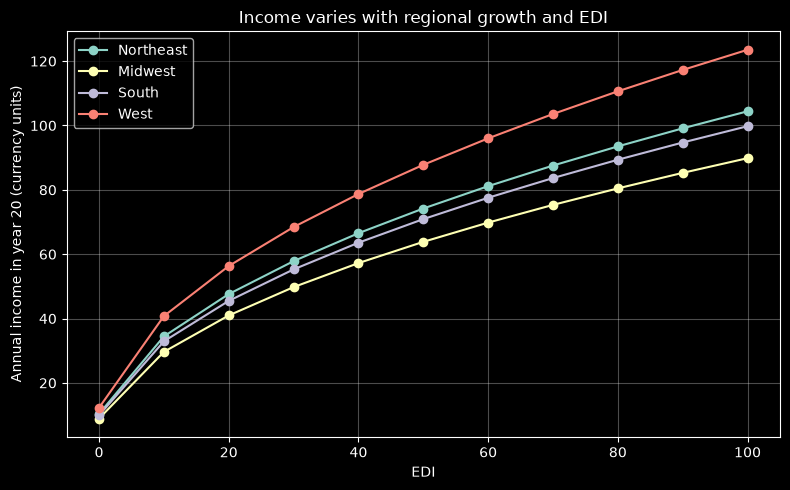

In [4]:
income_figure, income_axis = plt.subplots(figsize=(8, 5))
edi_levels = list(range(0, 101, 10))

for parameters in REGIONAL_ECONOMIC_PARAMETERS:
    income_values = []
    for edi in edi_levels:
        income_value = calculate_annual_income(
            parameters["annual_income"],
            parameters["annual_income_growth_rate"],
            20,
            edi,
            parameters["initial_edi"],
            STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"],
        )
        income_values.append(income_value)
    income_axis.plot(edi_levels, income_values, marker="o", label=parameters["region"])

income_axis.set_xlabel("EDI")
income_axis.set_ylabel("Annual income in year 20 (currency units)")
income_axis.set_title("Income varies with regional growth and EDI")
income_axis.grid(alpha=0.3)
income_axis.legend()
plt.tight_layout()
plt.show()

## Candidate emissions profile equation

For pollutant *p* and region *r*, the tested relative activity index is `I(p,r,t) = M(p,r) × [(1 + EDI(r,t)) / (1 + EDI0(r))]^εE`. `M` is the provisional regional profile multiplier and `εE` is a synthetic EDI-emissions elasticity. At initial EDI, the index equals the regional multiplier. The index has no physical units and is not passed to the Stage 1 pollutant equations. A later integration would require pollutant-specific activity-to-mass conversions.

In [5]:
emission_rows = []
selected_edi_levels = (0, 60, 80, 100)
emission_elasticity = STAGE_2_SCENARIOS["emission_edi_elasticity"]["reference"]

for pollutant, multipliers in REGIONAL_EMISSION_PROFILE_MULTIPLIERS.items():
    for region_index, parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        for edi in selected_edi_levels:
            activity_index = calculate_emission_activity_index(
                multipliers[region_index],
                edi,
                parameters["initial_edi"],
                emission_elasticity,
            )
            emission_rows.append({
                "pollutant_profile": pollutant,
                "region": parameters["region"],
                "edi": edi,
                "relative_emissions_index": activity_index,
            })

emission_profile_table = pd.DataFrame(emission_rows)
display(emission_profile_table.round(3))

,pollutant_profile,region,edi,relative_emissions_index
0,PM2.5,Northeast,0,0.030
1,PM2.5,Northeast,60,0.797
2,PM2.5,Northeast,80,1.000
3,PM2.5,Northeast,100,1.193
4,PM2.5,Midwest,0,0.045
...,...,...,...,...
59,Lead,South,100,1.603
60,Lead,West,0,0.025
61,Lead,West,60,0.671
62,Lead,West,80,0.842


The next tables vary one elasticity at a time. The income table compares annual income at EDI 100 in year 20; the emissions table compares the relative profile index at EDI 100. These ranges show how much the assumed elasticities affect the candidate equations.

In [6]:
income_sensitivity_rows = []
emissions_sensitivity_rows = []

for region_index, parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
    income_row = {"region": parameters["region"]}
    for scenario_level, elasticity in STAGE_2_SCENARIOS["income_edi_elasticity"].items():
        annual_income = calculate_annual_income(
            parameters["annual_income"],
            parameters["annual_income_growth_rate"],
            20,
            100,
            parameters["initial_edi"],
            elasticity,
        )
        income_row[f"income_{scenario_level}_elasticity"] = annual_income
    income_sensitivity_rows.append(income_row)

    for pollutant, multipliers in REGIONAL_EMISSION_PROFILE_MULTIPLIERS.items():
        emission_row = {"region": parameters["region"], "pollutant_profile": pollutant}
        for scenario_level, elasticity in STAGE_2_SCENARIOS["emission_edi_elasticity"].items():
            index_value = calculate_emission_activity_index(
                multipliers[region_index],
                100,
                parameters["initial_edi"],
                elasticity,
            )
            emission_row[f"index_{scenario_level}_elasticity"] = index_value
        emissions_sensitivity_rows.append(emission_row)

income_sensitivity_table = pd.DataFrame(income_sensitivity_rows)
emissions_sensitivity_table = pd.DataFrame(emissions_sensitivity_rows)
display(income_sensitivity_table.round(2))
display(emissions_sensitivity_table.round(3))

,region,income_low_elasticity,income_reference_elasticity,income_high_elasticity
0,Northeast,87.55,104.42,124.54
1,Midwest,69.82,89.84,115.60
2,South,74.30,99.78,134.00
3,West,107.16,123.53,142.40


,region,pollutant_profile,index_low_elasticity,index_reference_elasticity,index_high_elasticity
0,Northeast,PM2.5,1.036,1.193,1.374
1,Northeast,CO2,1.036,1.193,1.374
2,Northeast,Nitrate-N,0.921,1.061,1.221
3,Northeast,Lead,1.036,1.193,1.374
4,Midwest,PM2.5,1.468,1.796,2.198
5,Midwest,CO2,1.468,1.796,2.198
6,Midwest,Nitrate-N,1.713,2.096,2.564
7,Midwest,Lead,1.591,1.946,2.381
8,South,PM2.5,1.393,1.763,2.232
9,South,CO2,1.393,1.763,2.232


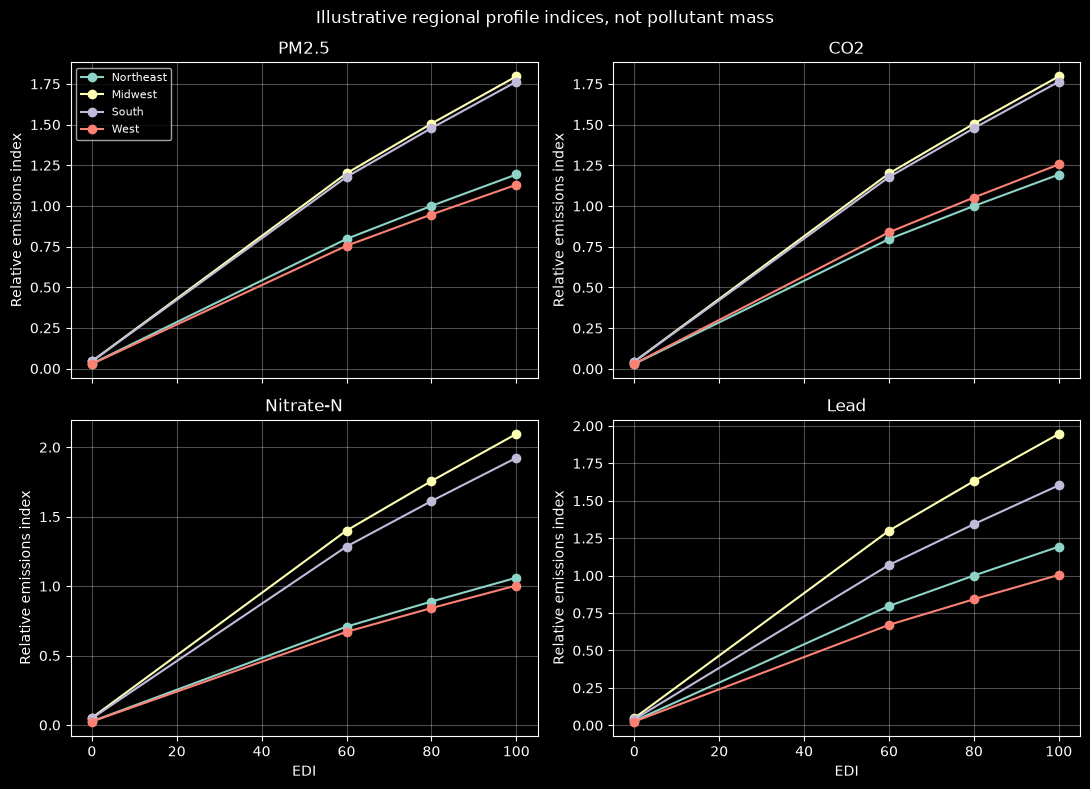

In [7]:
emission_figure, emission_axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
axes_flat = emission_axes.flat

for axis, pollutant in zip(axes_flat, REGIONAL_EMISSION_PROFILE_MULTIPLIERS):
    pollutant_rows = emission_profile_table[emission_profile_table["pollutant_profile"] == pollutant]
    for region_name in regional_parameters_table["region"]:
        region_rows = pollutant_rows[pollutant_rows["region"] == region_name]
        axis.plot(region_rows["edi"], region_rows["relative_emissions_index"], marker="o", label=region_name)
    axis.set_title(pollutant)
    axis.set_ylabel("Relative emissions index")
    axis.grid(alpha=0.3)

emission_axes[1, 0].set_xlabel("EDI")
emission_axes[1, 1].set_xlabel("EDI")
emission_axes[0, 0].legend(fontsize=8)
emission_figure.suptitle("Illustrative regional profile indices, not pollutant mass")
plt.tight_layout()
plt.show()

## Checks and interpretation

The checks verify the chosen equations, not whether the parameter values describe real regional economies. These inputs should be replaced with comparable BEA or Census estimates before they are described as empirical. The growth rates also lack an inflation/deflator basis, so all currency values remain abstract scenario units.

In [8]:
check_rows = []

for parameters in REGIONAL_ECONOMIC_PARAMETERS:
    baseline_income = calculate_annual_income(
        parameters["annual_income"],
        parameters["annual_income_growth_rate"],
        0,
        parameters["initial_edi"],
        parameters["initial_edi"],
        STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"],
    )
    income_at_starting_edi = calculate_annual_income(
        parameters["annual_income"],
        parameters["annual_income_growth_rate"],
        20,
        parameters["initial_edi"],
        parameters["initial_edi"],
        STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"],
    )
    income_at_edi_zero = calculate_annual_income(
        parameters["annual_income"], parameters["annual_income_growth_rate"], 20, 0,
        parameters["initial_edi"], STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"]
    )
    income_at_edi_100 = calculate_annual_income(
        parameters["annual_income"], parameters["annual_income_growth_rate"], 20, 100,
        parameters["initial_edi"], STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"]
    )
    expected_income = parameters["annual_income"] * (1 + parameters["annual_income_growth_rate"]) ** 20
    check_rows.append({
        "check": f"{parameters['region']} starting income matches baseline",
        "passed": abs(baseline_income - parameters["annual_income"]) < 1e-10,
    })
    check_rows.append({
        "check": f"{parameters['region']} frozen-EDI income follows compound growth",
        "passed": abs(income_at_starting_edi - expected_income) < 1e-10,
    })
    check_rows.append({
        "check": f"{parameters['region']} income increases with EDI under positive elasticity",
        "passed": income_at_edi_100 > income_at_edi_zero,
    })

for pollutant, multipliers in REGIONAL_EMISSION_PROFILE_MULTIPLIERS.items():
    for region_index, parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        starting_index = calculate_emission_activity_index(
            multipliers[region_index], parameters["initial_edi"], parameters["initial_edi"], emission_elasticity
        )
        check_rows.append({
            "check": f"{pollutant} {parameters['region']} index starts at its profile multiplier",
            "passed": abs(starting_index - multipliers[region_index]) < 1e-12,
        })
        low_edi_index = calculate_emission_activity_index(
            multipliers[region_index], 0, parameters["initial_edi"], emission_elasticity
        )
        high_edi_index = calculate_emission_activity_index(
            multipliers[region_index], 100, parameters["initial_edi"], emission_elasticity
        )
        check_rows.append({
            "check": f"{pollutant} {parameters['region']} index rises with EDI under positive elasticity",
            "passed": high_edi_index > low_edi_index,
        })

checks_table = pd.DataFrame(check_rows)
display(checks_table)
print(f"Passed {checks_table['passed'].sum()} of {len(checks_table)} mathematical checks.")

,check,passed
0,Northeast starting income matches baseline,True
1,Northeast frozen-EDI income follows compound g...,True
2,Northeast income increases with EDI under posi...,True
3,Midwest starting income matches baseline,True
4,Midwest frozen-EDI income follows compound growth,True
5,Midwest income increases with EDI under positi...,True
6,South starting income matches baseline,True
7,South frozen-EDI income follows compound growth,True
8,South income increases with EDI under positive...,True
9,West starting income matches baseline,True


Passed 44 of 44 mathematical checks.
